# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Muhammad Dikaisa Ibnu Amin
- **Email:** muhammaddikaisa1@gmail.com
- **ID Dicoding:** Muhammad dikaisa ibnu amin

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**: pertanyaan jelas, fokus pada satu topik, tidak bermakna ganda.
* **Measurable (Terukur)**: bisa dijawab dengan angka atau metrik yang konkret.
* **Action-Oriented (Berorientasi Aksi)**: jawabannya memberi arahan tindakan nyata bagi stakeholder.
* **Relevant (Relevan)**: sejalan dengan tujuan utama bisnis.
* **Time-bound (Terikat Waktu)**: punya batasan waktu yang jelas.

Pada proyek ini, periode analisis dibatasi **Januari 2017 – Agustus 2018** karena hanya bulan-bulan tersebut yang datanya lengkap (September–Desember 2016 dan September–Oktober 2018 hanya berisi sangat sedikit pesanan).

- **Pertanyaan 1:** Apa saja 5 kategori produk dengan total revenue tertinggi dan 5 kategori dengan total revenue terendah dari pesanan yang berhasil terkirim (*delivered*) selama Januari 2017 – Agustus 2018, sehingga tim marketing dapat menentukan kategori yang diprioritaskan untuk promosi dan kategori yang perlu dievaluasi?
- **Pertanyaan 2:** Bagaimana tren jumlah pesanan dan total revenue per bulan selama Januari 2017 – Agustus 2018, dan pada bulan apa terjadi puncak penjualan, sebagai dasar perencanaan stok dan jadwal kampanye?
- **Pertanyaan 3:** Berapa selisih rata-rata skor review (skala 1–5) antara pesanan yang terlambat diterima dibandingkan pesanan yang tepat waktu selama Januari 2017 – Agustus 2018, dan berapa persentase pesanan terlambat per state, sebagai dasar perbaikan layanan logistik?

| Elemen | Pertanyaan 1 | Pertanyaan 2 | Pertanyaan 3 |
|---|---|---|---|
| Specific | Revenue per kategori produk | Jumlah pesanan & revenue bulanan | Skor review terlambat vs tepat waktu |
| Measurable | Total revenue (BRL) | Jumlah order, total revenue, pertumbuhan MoM | Rata-rata skor review, % keterlambatan |
| Action-Oriented | Prioritas promosi & evaluasi kategori | Perencanaan stok & kampanye | Perbaikan logistik di state bermasalah |
| Relevant | Penjualan adalah KPI utama e-commerce | Musiman penjualan memengaruhi operasional | Kepuasan pelanggan memengaruhi retensi |
| Time-bound | Jan 2017 – Agu 2018 | Jan 2017 – Agu 2018 | Jan 2017 – Agu 2018 |

## Import Semua Packages/Library yang Digunakan

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import folium

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

## Data Wrangling

### Gathering Data

Dataset terdiri dari beberapa tabel yang saling berelasi melalui `order_id`, `customer_id`, `product_id`, dan `customer_zip_code_prefix`. Semua file CSV disimpan di folder `data/`.

> Jika dijalankan di Google Colab, upload folder `data/` terlebih dahulu (atau unduh dataset dengan `gdown` lalu ekstrak ke folder `data/`).

#### Load tabel orders, order_items, products, dan product_category_name_translation

In [4]:
DATA_PATH = "data/"

orders_df = pd.read_csv(DATA_PATH + "orders_dataset.csv")
order_items_df = pd.read_csv(DATA_PATH + "order_items_dataset.csv")
products_df = pd.read_csv(DATA_PATH + "products_dataset.csv")
category_df = pd.read_csv(DATA_PATH + "product_category_name_translation.csv", encoding="utf-8-sig")

orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [5]:
order_items_df.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [6]:
products_df.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


#### Load tabel customers, order_payments, order_reviews, dan geolocation

In [7]:
customers_df = pd.read_csv(DATA_PATH + "customers_dataset.csv")
payments_df = pd.read_csv(DATA_PATH + "order_payments_dataset.csv")
reviews_df = pd.read_csv(DATA_PATH + "order_reviews_dataset.csv")
geolocation_df = pd.read_csv(DATA_PATH + "geolocation_dataset.csv")

for name, df in {"orders": orders_df, "order_items": order_items_df, "products": products_df,
                 "category": category_df, "customers": customers_df, "payments": payments_df,
                 "reviews": reviews_df, "geolocation": geolocation_df}.items():
    print(f"{name:<12}: {df.shape[0]:>9,} baris, {df.shape[1]} kolom")

orders      :    99,441 baris, 8 kolom
order_items :   112,650 baris, 7 kolom
products    :    32,951 baris, 9 kolom
category    :        71 baris, 2 kolom
customers   :    99,441 baris, 5 kolom
payments    :   103,886 baris, 5 kolom
reviews     :    99,224 baris, 7 kolom
geolocation : 1,000,163 baris, 5 kolom


In [8]:
reviews_df.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


**Insight:**
- Dataset terdiri dari 8 tabel yang dipakai (orders, order_items, products, category translation, customers, payments, reviews, geolocation) dan saling terhubung lewat order_id, customer_id, product_id, serta zip code prefix.
- Tabel orders berisi 99.441 pesanan, sedangkan order_items berisi 112.650 baris karena satu pesanan bisa berisi lebih dari satu produk.
- Tabel geolocation paling besar (1.000.163 baris) karena satu kode pos bisa punya banyak titik koordinat.

### Assessing Data

#### Identifying tipe data dan missing value pada orders_df

In [9]:
orders_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [10]:
print("Missing value orders_df:")
print(orders_df.isna().sum())
print("\nDuplikat:", orders_df.duplicated().sum())
print("\nStatus pesanan:")
print(orders_df["order_status"].value_counts())

Missing value orders_df:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Duplikat: 0

Status pesanan:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [11]:
# Distribusi pesanan per bulan untuk menentukan periode yang datanya lengkap
pd.to_datetime(orders_df["order_purchase_timestamp"]).dt.to_period("M").value_counts().sort_index()

,count
order_purchase_timestamp,
2016-09,4
2016-10,324
2016-12,1
2017-01,800
2017-02,1780
2017-03,2682
2017-04,2404
2017-05,3700
2017-06,3245


#### Identifying missing value dan inconsistent value pada products_df

In [12]:
print("Missing value products_df:")
print(products_df.isna().sum())

missing_translation = set(products_df["product_category_name"].dropna()) - set(category_df["product_category_name"])
print("\nKategori yang tidak punya terjemahan:", missing_translation)

Missing value products_df:
product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

Kategori yang tidak punya terjemahan: {'pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos'}


#### Identifying tipe data dan outlier pada order_items_df

In [13]:
order_items_df.info()
order_items_df[["price", "freight_value"]].describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  object 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  object 
 3   seller_id            112650 non-null  object 
 4   shipping_limit_date  112650 non-null  object 
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 6.0+ MB


,price,freight_value
count,112650.000000,112650.000000
mean,120.653739,20.031952
std,183.633928,16.017651
min,0.850000,0.000000
25%,39.900000,13.080000
50%,74.990000,16.270000
75%,134.900000,21.150000
max,6735.000000,409.680000


In [14]:
Q1, Q3 = order_items_df["price"].quantile([0.25, 0.75])
IQR = Q3 - Q1
upper = Q3 + 1.5 * IQR
print(f"Batas atas outlier price (IQR): {upper:.2f}")
print(f"Jumlah item dengan price di atas batas: {(order_items_df['price'] > upper).sum():,}")

Batas atas outlier price (IQR): 277.40
Jumlah item dengan price di atas batas: 8,427


#### Identifying invalid value pada payments_df

In [15]:
print(payments_df["payment_type"].value_counts())
print("\nPembayaran dengan cicilan 0:", (payments_df["payment_installments"] == 0).sum())
print("Pembayaran dengan nilai 0:", (payments_df["payment_value"] == 0).sum())

payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64

Pembayaran dengan cicilan 0: 2
Pembayaran dengan nilai 0: 9


#### Identifying duplicate dan missing value pada reviews_df

In [16]:
print("Missing value reviews_df:")
print(reviews_df.isna().sum())
print("\nOrder yang punya lebih dari 1 review:", reviews_df["order_id"].duplicated().sum())

Missing value reviews_df:
review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64

Order yang punya lebih dari 1 review: 551


#### Identifying duplicate dan invalid value pada geolocation_df

In [17]:
print("Duplikat geolocation_df:", geolocation_df.duplicated().sum())

# Batas koordinat wilayah Brasil (perkiraan)
outside_brazil = ~(geolocation_df["geolocation_lat"].between(-33.75, 5.27) &
                   geolocation_df["geolocation_lng"].between(-73.99, -34.79))
print("Koordinat di luar wilayah Brasil:", outside_brazil.sum())

Duplikat geolocation_df: 261831
Koordinat di luar wilayah Brasil: 42


**Steps to Take:**
- **orders_df**: ubah kolom tanggal dari `object` ke `datetime`; untuk analisis gunakan hanya pesanan berstatus `delivered` (missing value pada tanggal pengiriman umumnya berasal dari pesanan yang batal/belum terkirim); batasi periode Januari 2017 – Agustus 2018.
- **products_df**: isi kategori yang kosong dengan `unknown`, tambahkan terjemahan untuk 2 kategori yang belum ada di tabel translation, lalu gabungkan dengan nama kategori bahasa Inggris.
- **order_items_df**: ubah `shipping_limit_date` ke `datetime`. Outlier harga **tidak dihapus** karena merupakan transaksi nyata (produk mahal), bukan kesalahan input.
- **payments_df**: hapus baris dengan `payment_type` = `not_defined`.
- **reviews_df**: untuk pesanan yang punya lebih dari satu review, simpan review terbaru (berdasarkan `review_answer_timestamp`) agar satu pesanan hanya punya satu skor. Kolom komentar yang kosong dibiarkan karena tidak dipakai.
- **geolocation_df**: hapus duplikat dan koordinat di luar wilayah Brasil, lalu agregasi menjadi titik tengah per state.

**Insight:**
- Semua kolom tanggal di orders_df dan order_items_df masih bertipe string sehingga perlu diubah ke datetime.
- Missing value terbesar ada di order_delivered_customer_date (2.965 baris), sebagian besar dari pesanan yang belum/tidak terkirim (status selain delivered).
- Data per bulan tidak lengkap di awal (Sep–Des 2016) dan akhir (Sep–Okt 2018), sehingga periode analisis dibatasi Jan 2017 – Agu 2018.
- products_df punya 610 produk tanpa kategori, dan 2 kategori (pc_gamer dan portateis_cozinha_e_preparadores_de_alimentos) tidak punya terjemahan (inconsistent value).
- Terdapat 8.427 item dengan harga di atas batas IQR (BRL 277,40). Ini outlier wajar dari produk mahal, bukan kesalahan input.
- Ditemukan 3 pembayaran dengan payment_type not_defined (invalid), 551 pesanan dengan review ganda, serta 261.831 baris duplikat dan 42 koordinat di luar Brasil pada geolocation_df.

### Cleaning Data

#### Fixing tipe data dan filter pesanan pada orders_df

In [18]:
date_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
             "order_delivered_customer_date", "order_estimated_delivery_date"]
for col in date_cols:
    orders_df[col] = pd.to_datetime(orders_df[col])

orders_clean = orders_df[
    (orders_df["order_status"] == "delivered") &
    (orders_df["order_purchase_timestamp"] >= "2017-01-01") &
    (orders_df["order_purchase_timestamp"] < "2018-09-01")
].copy()

# Pesanan delivered yang tanggal terimanya kosong tidak bisa dihitung keterlambatannya
orders_clean = orders_clean.dropna(subset=["order_delivered_customer_date"])

print("Sebelum:", orders_df.shape[0], "| Sesudah:", orders_clean.shape[0])
orders_clean.info()

Sebelum: 99441 | Sesudah: 96203
<class 'pandas.core.frame.DataFrame'>
Index: 96203 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       96203 non-null  object        
 1   customer_id                    96203 non-null  object        
 2   order_status                   96203 non-null  object        
 3   order_purchase_timestamp       96203 non-null  datetime64[ns]
 4   order_approved_at              96189 non-null  datetime64[ns]
 5   order_delivered_carrier_date   96202 non-null  datetime64[ns]
 6   order_delivered_customer_date  96203 non-null  datetime64[ns]
 7   order_estimated_delivery_date  96203 non-null  datetime64[ns]
dtypes: datetime64[ns](5), object(3)
memory usage: 6.6+ MB


#### Fixing missing value dan inconsistent value pada products_df

In [19]:
extra_translation = pd.DataFrame({
    "product_category_name": ["portateis_cozinha_e_preparadores_de_alimentos", "pc_gamer"],
    "product_category_name_english": ["portable_kitchen_and_food_preparers", "pc_gamer"],
})
category_full = pd.concat([category_df, extra_translation], ignore_index=True)

products_clean = products_df.merge(category_full, on="product_category_name", how="left")
products_clean["product_category_name_english"] = products_clean["product_category_name_english"].fillna("unknown")

print("Kategori kosong setelah cleaning:", products_clean["product_category_name_english"].isna().sum())
print("Jumlah kategori:", products_clean["product_category_name_english"].nunique())

Kategori kosong setelah cleaning: 0
Jumlah kategori: 74


#### Fixing tipe data pada order_items_df dan invalid value pada payments_df

In [20]:
order_items_df["shipping_limit_date"] = pd.to_datetime(order_items_df["shipping_limit_date"])

payments_clean = payments_df[payments_df["payment_type"] != "not_defined"].copy()
print("payment_type setelah cleaning:", payments_clean["payment_type"].unique())

payment_type setelah cleaning: ['credit_card' 'boleto' 'voucher' 'debit_card']


#### Fixing duplicate pada reviews_df

In [21]:
reviews_df["review_answer_timestamp"] = pd.to_datetime(reviews_df["review_answer_timestamp"])
reviews_clean = (reviews_df.sort_values("review_answer_timestamp")
                 .drop_duplicates(subset="order_id", keep="last")[["order_id", "review_score"]])
print("Order dengan >1 review setelah cleaning:", reviews_clean["order_id"].duplicated().sum())

Order dengan >1 review setelah cleaning: 0


#### Fixing duplicate dan invalid value pada geolocation_df

In [22]:
geo_clean = geolocation_df.drop_duplicates()
geo_clean = geo_clean[geo_clean["geolocation_lat"].between(-33.75, 5.27) &
                      geo_clean["geolocation_lng"].between(-73.99, -34.79)]

geo_state = (geo_clean.groupby("geolocation_state", as_index=False)
             .agg(lat=("geolocation_lat", "median"), lng=("geolocation_lng", "median"))
             .rename(columns={"geolocation_state": "state"}))
print("Baris geolocation:", geolocation_df.shape[0], "->", geo_clean.shape[0])
geo_state.head()

Baris geolocation: 1000163 -> 738299


,state,lat,lng
0,AC,-9.961648,-67.831102
1,AL,-9.636258,-35.756508
2,AM,-3.090152,-60.010616
3,AP,0.031209,-51.073509
4,BA,-12.948131,-38.998427


#### Menggabungkan tabel menjadi satu DataFrame utama

In [23]:
main_df = (orders_clean
           .merge(order_items_df, on="order_id", how="inner")
           .merge(products_clean[["product_id", "product_category_name_english"]], on="product_id", how="left")
           .merge(customers_df, on="customer_id", how="left")
           .merge(reviews_clean, on="order_id", how="left"))

main_df["is_late"] = main_df["order_delivered_customer_date"] > main_df["order_estimated_delivery_date"]
main_df["delivery_days"] = (main_df["order_delivered_customer_date"] - main_df["order_purchase_timestamp"]).dt.days
main_df["order_month"] = main_df["order_purchase_timestamp"].dt.to_period("M").astype(str)

print(main_df.shape)
main_df.head()

(109872, 23)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name_english,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,review_score,is_late,delivery_days,order_month
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72,housewares,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,4.0,False,8,2017-10
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76,perfumery,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,4.0,False,13,2018-07
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22,auto,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,5.0,False,9,2018-08
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,1,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,2017-11-23 19:45:59,45.00,27.20,pet_shop,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN,5.0,False,13,2017-11
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,1,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,2018-02-19 20:31:37,19.90,8.72,stationery,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP,5.0,False,2,2018-02


**Insight:**
- Setelah filter status delivered dan periode Jan 2017 – Agu 2018, tersisa 96.203 pesanan dengan tipe data tanggal yang sudah benar.
- Semua produk kini punya nama kategori bahasa Inggris (74 kategori, termasuk 'unknown' untuk produk tanpa kategori).
- Review ganda diselesaikan dengan menyimpan review terbaru, dan geolocation berkurang dari 1.000.163 menjadi 738.299 baris lalu diringkas menjadi 27 titik state.
- Tabel digabung menjadi main_df (109.872 baris item) dan ditambah kolom bantu is_late, delivery_days, serta order_month untuk analisis.

## Exploratory Data Analysis (EDA)

### Explore ringkasan statistik main_df

In [24]:
main_df[["price", "freight_value", "review_score", "delivery_days"]].describe()

,price,freight_value,review_score,delivery_days
count,109872.000000,109872.000000,109049.000000,109872.000000
mean,119.955748,19.992837,4.082449,11.985993
std,182.351343,15.922124,1.346612,9.433554
min,0.850000,0.000000,1.000000,0.000000
25%,39.900000,13.080000,4.000000,6.000000
50%,74.900000,16.260000,5.000000,10.000000
75%,134.042500,21.150000,5.000000,15.000000
max,6735.000000,409.680000,5.000000,209.000000


In [25]:
print("Jumlah pesanan unik :", main_df["order_id"].nunique())
print("Jumlah pelanggan unik:", main_df["customer_unique_id"].nunique())
print(f"Total revenue       : BRL {main_df['price'].sum():,.0f}")

Jumlah pesanan unik : 96203
Jumlah pelanggan unik: 93096
Total revenue       : BRL 13,179,778


### Explore revenue per kategori produk (Pertanyaan 1)

In [26]:
category_rev = (main_df.groupby("product_category_name_english")
                .agg(revenue=("price", "sum"), orders=("order_id", "nunique"), items=("order_item_id", "count"))
                .sort_values("revenue", ascending=False))
category_rev.head(10)

,revenue,orders,items
product_category_name_english,,,
health_beauty,1229557.50,8610,9422
watches_gifts,1163187.91,5489,5853
bed_bath_table,1022955.77,9267,10945
sports_leisure,952661.40,7512,8413
computers_accessories,887944.60,6517,7631
furniture_decor,706237.17,6258,8095
housewares,614341.62,5734,6783
cool_stuff,609158.00,3552,3711
auto,577721.09,3801,4131


In [27]:
category_rev.tail(10)

,revenue,orders,items
product_category_name_english,,,
fashion_sport,2094.52,26,29
la_cuisine,2054.99,13,14
arts_and_craftmanship,1814.01,23,24
diapers_and_hygiene,1365.89,24,36
pc_gamer,1306.95,7,8
flowers,1110.04,29,33
home_comfort_2,760.27,24,30
cds_dvds_musicals,730.00,12,14
fashion_childrens_clothes,519.95,7,7


### Explore tren pesanan dan revenue bulanan (Pertanyaan 2)

In [28]:
monthly_df = (main_df.groupby("order_month")
              .agg(orders=("order_id", "nunique"), revenue=("price", "sum"))
              .reset_index())
monthly_df["revenue_growth_%"] = (monthly_df["revenue"].pct_change() * 100).round(1)
monthly_df

,order_month,orders,revenue,revenue_growth_%
0,2017-01,750,111798.36,NaN
1,2017-02,1653,234223.40,109.5
2,2017-03,2546,359198.85,53.4
3,2017-04,2303,340669.68,-5.2
4,2017-05,3545,489159.25,43.6
5,2017-06,3135,421923.37,-13.7
6,2017-07,3872,481604.52,14.1
7,2017-08,4193,554699.70,15.2
8,2017-09,4150,607399.67,9.5
9,2017-10,4478,648247.65,6.7


### Explore keterlambatan pengiriman dan skor review (Pertanyaan 3)

In [29]:
order_level = main_df.drop_duplicates("order_id")

late_review = order_level.groupby("is_late")["review_score"].agg(["mean", "count"])
late_review.index = late_review.index.map({False: "Tepat waktu", True: "Terlambat"})
print(late_review)
print(f"\nPersentase pesanan terlambat: {order_level['is_late'].mean():.1%}")

                 mean  count
is_late                     
Tepat waktu  4.294908  87902
Terlambat    2.565291   7658

Persentase pesanan terlambat: 8.1%


In [30]:
order_level.groupby("is_late")["review_score"].value_counts(normalize=True).unstack().round(3)

review_score,1.0,2.0,3.0,4.0,5.0
is_late,,,,,
False,0.066,0.026,0.080,0.204,0.625
True,0.462,0.079,0.114,0.123,0.222


In [31]:
state_late = (order_level.groupby("customer_state")
              .agg(orders=("order_id", "nunique"), late_rate=("is_late", "mean"))
              .sort_values("late_rate", ascending=False))
state_late.head(10)

,orders,late_rate
customer_state,,
AL,396,0.239899
MA,713,0.196353
PI,475,0.160000
CE,1273,0.153967
SE,332,0.153614
BA,3253,0.140486
RJ,12310,0.135175
TO,274,0.127737
RR,40,0.125000


**Insight:**
- Pada Jan 2017 – Agu 2018 terdapat 96.203 pesanan dari 93.096 pelanggan unik dengan total revenue produk sekitar BRL 13,18 juta.
- 5 kategori teratas (health_beauty, watches_gifts, bed_bath_table, sports_leisure, computers_accessories) menyumbang sekitar 40% dari total revenue, sedangkan kategori terbawah seperti security_and_services hanya punya 2 pesanan.
- Jumlah pesanan naik tajam di November 2017 (7.288 pesanan, +52% revenue dari Oktober). Lonjakan terbesar terjadi pada 24 November 2017 (Black Friday) dengan 1.147 pesanan dalam sehari.
- Periode Jan–Agu 2018 tumbuh sekitar 140% dibanding Jan–Agu 2017, baik dari jumlah pesanan maupun revenue, tetapi tren 2018 cenderung stagnan di kisaran 6.000–7.000 pesanan per bulan.
- Sebanyak 8,1% pesanan terlambat. Rata-rata skor review pesanan terlambat hanya 2,57, jauh di bawah pesanan tepat waktu (4,29), dan 46% pesanan terlambat mendapat bintang 1.
- State dengan keterlambatan tertinggi adalah AL (24,0%), MA (19,6%), dan PI (16,0%). RJ juga perlu diperhatikan karena volumenya besar (12.310 pesanan) dengan keterlambatan 13,5%.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Kategori produk dengan revenue tertinggi dan terendah (Jan 2017 – Agu 2018)

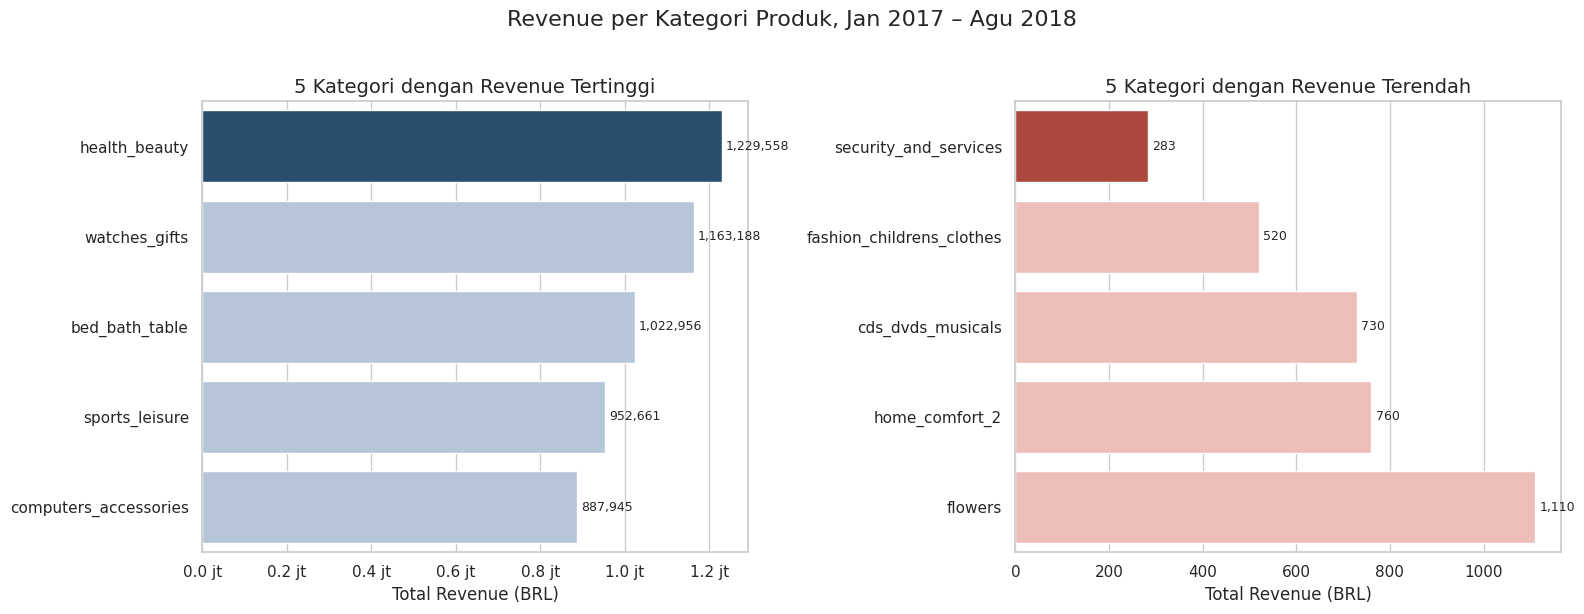

In [32]:
top5 = category_rev.head(5).reset_index()
bottom5 = category_rev.tail(5).sort_values("revenue").reset_index()

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
colors_top = ["#1f4e79"] + ["#b0c4de"] * 4
colors_bot = ["#c0392b"] + ["#f5b7b1"] * 4

sns.barplot(data=top5, x="revenue", y="product_category_name_english", palette=colors_top, ax=ax[0], hue="product_category_name_english", legend=False)
ax[0].set_title("5 Kategori dengan Revenue Tertinggi", fontsize=14)
ax[0].set_xlabel("Total Revenue (BRL)")
ax[0].set_ylabel(None)
ax[0].xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1e6:.1f} jt"))

sns.barplot(data=bottom5, x="revenue", y="product_category_name_english", palette=colors_bot, ax=ax[1], hue="product_category_name_english", legend=False)
ax[1].set_title("5 Kategori dengan Revenue Terendah", fontsize=14)
ax[1].set_xlabel("Total Revenue (BRL)")
ax[1].set_ylabel(None)

for a in ax:
    for c in a.containers:
        a.bar_label(c, fmt="{:,.0f}", padding=3, fontsize=9)

plt.suptitle("Revenue per Kategori Produk, Jan 2017 – Agu 2018", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

### Pertanyaan 2: Tren jumlah pesanan dan revenue bulanan (Jan 2017 – Agu 2018)

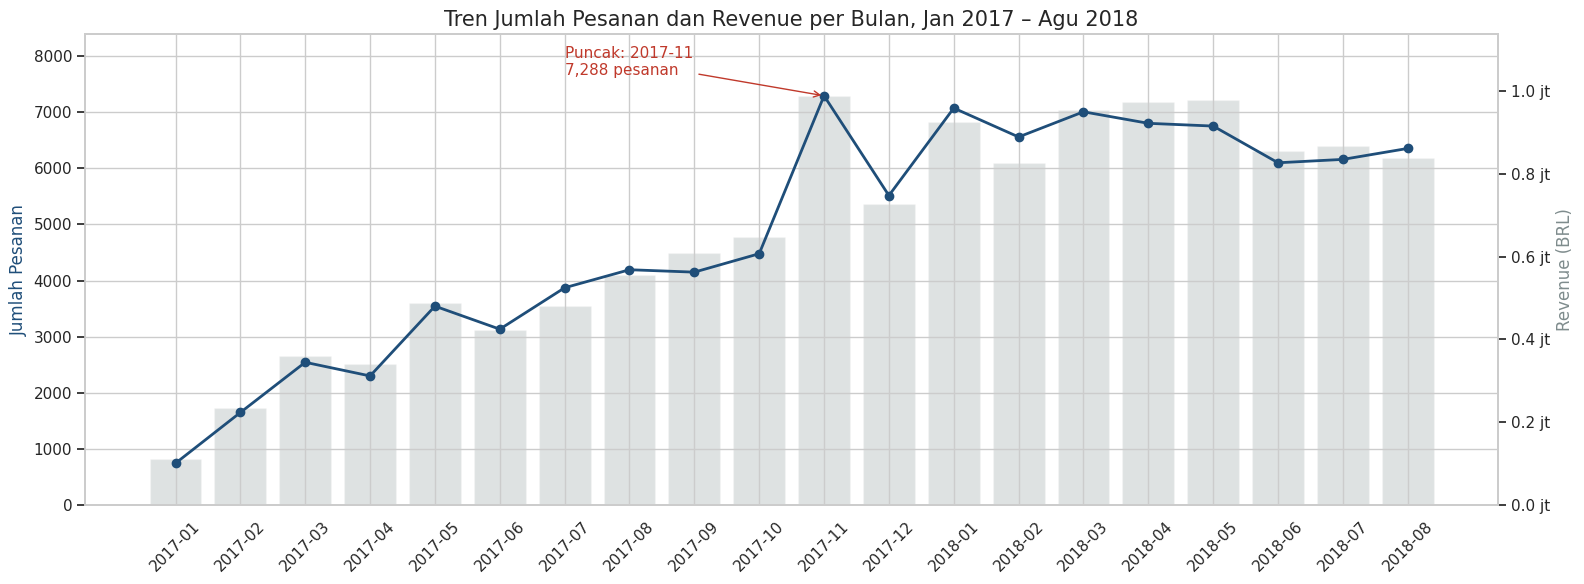

In [33]:
fig, ax1 = plt.subplots(figsize=(16, 6))
x = monthly_df["order_month"]
peak_idx = monthly_df["orders"].idxmax()

ax1.plot(x, monthly_df["orders"], marker="o", linewidth=2, color="#1f4e79", label="Jumlah pesanan")
ax1.set_ylabel("Jumlah Pesanan", color="#1f4e79")
ax1.set_ylim(0, monthly_df["orders"].max() * 1.15)
ax1.tick_params(axis="x", rotation=45)

ax2 = ax1.twinx()
ax2.bar(x, monthly_df["revenue"], alpha=0.25, color="#7f8c8d", label="Revenue")
ax2.set_ylabel("Revenue (BRL)", color="#7f8c8d")
ax2.set_ylim(0, monthly_df["revenue"].max() * 1.15)
ax2.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1e6:.1f} jt"))
ax2.grid(False)

ax1.annotate(f"Puncak: {x[peak_idx]}\n{monthly_df['orders'][peak_idx]:,} pesanan",
             xy=(peak_idx, monthly_df["orders"][peak_idx]),
             xytext=(peak_idx - 4, monthly_df["orders"][peak_idx] * 1.05),
             arrowprops=dict(arrowstyle="->", color="#c0392b"), color="#c0392b", fontsize=11)

ax1.set_zorder(ax2.get_zorder() + 1)
ax1.patch.set_visible(False)
ax1.set_title("Tren Jumlah Pesanan dan Revenue per Bulan, Jan 2017 – Agu 2018", fontsize=15)
ax1.set_xlabel(None)
plt.tight_layout()
plt.show()

### Pertanyaan 3: Pengaruh keterlambatan pengiriman terhadap skor review (Jan 2017 – Agu 2018)

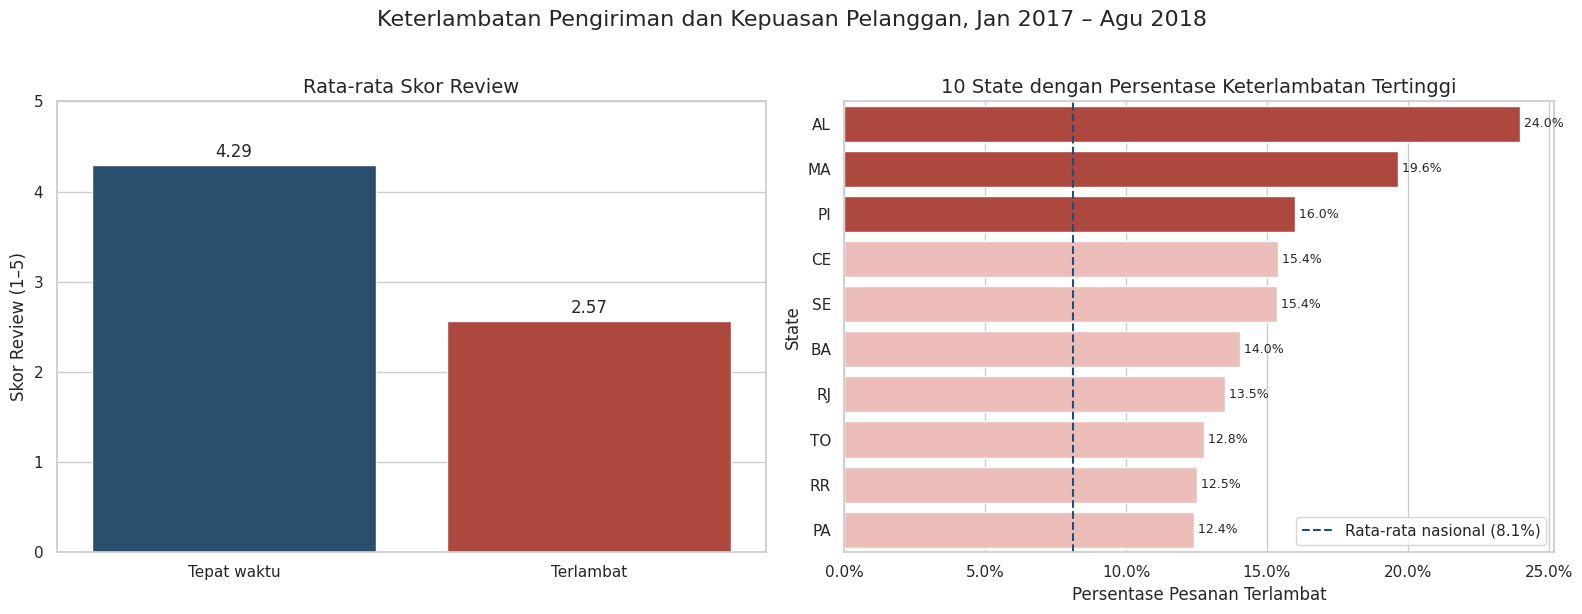

In [34]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

lr = late_review.reset_index().rename(columns={"is_late": "status"})
sns.barplot(data=lr, x="status", y="mean", hue="status", palette=["#1f4e79", "#c0392b"], legend=False, ax=ax[0])
ax[0].set_ylim(0, 5)
ax[0].set_title("Rata-rata Skor Review", fontsize=14)
ax[0].set_xlabel(None)
ax[0].set_ylabel("Skor Review (1–5)")
ax[0].bar_label(ax[0].containers[0], fmt="%.2f", padding=3)
ax[0].bar_label(ax[0].containers[1], fmt="%.2f", padding=3)

top_state = state_late.head(10).reset_index()
avg_late = order_level["is_late"].mean()
colors = ["#c0392b"] * 3 + ["#f5b7b1"] * 7
sns.barplot(data=top_state, x="late_rate", y="customer_state", hue="customer_state", palette=colors, legend=False, ax=ax[1])
ax[1].axvline(avg_late, color="#1f4e79", linestyle="--", label=f"Rata-rata nasional ({avg_late:.1%})")
ax[1].xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax[1].set_title("10 State dengan Persentase Keterlambatan Tertinggi", fontsize=14)
ax[1].set_xlabel("Persentase Pesanan Terlambat")
ax[1].set_ylabel("State")
for i, v in enumerate(top_state["late_rate"]):
    ax[1].text(v, i, f" {v:.1%}", va="center", fontsize=9)
ax[1].legend(loc="lower right")

plt.suptitle("Keterlambatan Pengiriman dan Kepuasan Pelanggan, Jan 2017 – Agu 2018", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

**Insight:**
- Pertanyaan 1: health_beauty menjadi kategori dengan revenue tertinggi (BRL 1,23 juta), diikuti watches_gifts dan bed_bath_table. Kategori terendah adalah security_and_services (BRL 283), fashion_childrens_clothes, dan cds_dvds_musicals.
- Pertanyaan 2: tren pesanan dan revenue naik sepanjang 2017 dengan puncak di November 2017 (efek Black Friday), lalu stabil tinggi di 2018 dengan revenue tertinggi pada April–Mei 2018 (sekitar BRL 0,97 juta per bulan).
- Pertanyaan 3: keterlambatan menurunkan rata-rata skor review sebesar 1,73 poin (4,29 → 2,57). Keterlambatan paling tinggi terjadi di state wilayah utara dan timur laut (AL, MA, PI, CE, SE).

## Analisis Lanjutan (Opsional)

### RFM Analysis
**Tujuan:** mengelompokkan pelanggan berdasarkan perilaku belanja agar tim marketing bisa memberi perlakuan berbeda per segmen.
- **Recency**: jumlah hari sejak pembelian terakhir pelanggan sampai tanggal acuan (1 hari setelah transaksi terakhir di dataset).
- **Frequency**: jumlah pesanan unik per pelanggan selama Jan 2017 – Agu 2018.
- **Monetary**: total belanja (harga produk) per pelanggan pada periode tersebut.

Pelanggan diidentifikasi dengan `customer_unique_id` karena satu orang bisa punya beberapa `customer_id`.

In [35]:
snapshot_date = main_df["order_purchase_timestamp"].max() + pd.Timedelta(days=1)

rfm_df = (main_df.groupby("customer_unique_id")
          .agg(last_purchase=("order_purchase_timestamp", "max"),
               frequency=("order_id", "nunique"),
               monetary=("price", "sum"))
          .reset_index())
rfm_df["recency"] = (snapshot_date - rfm_df["last_purchase"]).dt.days
rfm_df.drop(columns="last_purchase", inplace=True)
rfm_df[["recency", "frequency", "monetary"]].describe()

,recency,frequency,monetary
count,93096.000000,93096.000000,93096.000000
mean,236.711137,1.033374,141.571904
std,150.940603,0.209021,215.768405
min,1.000000,1.000000,0.850000
25%,114.000000,1.000000,47.650000
50%,218.000000,1.000000,89.700000
75%,345.000000,1.000000,154.162500
max,602.000000,15.000000,13440.000000


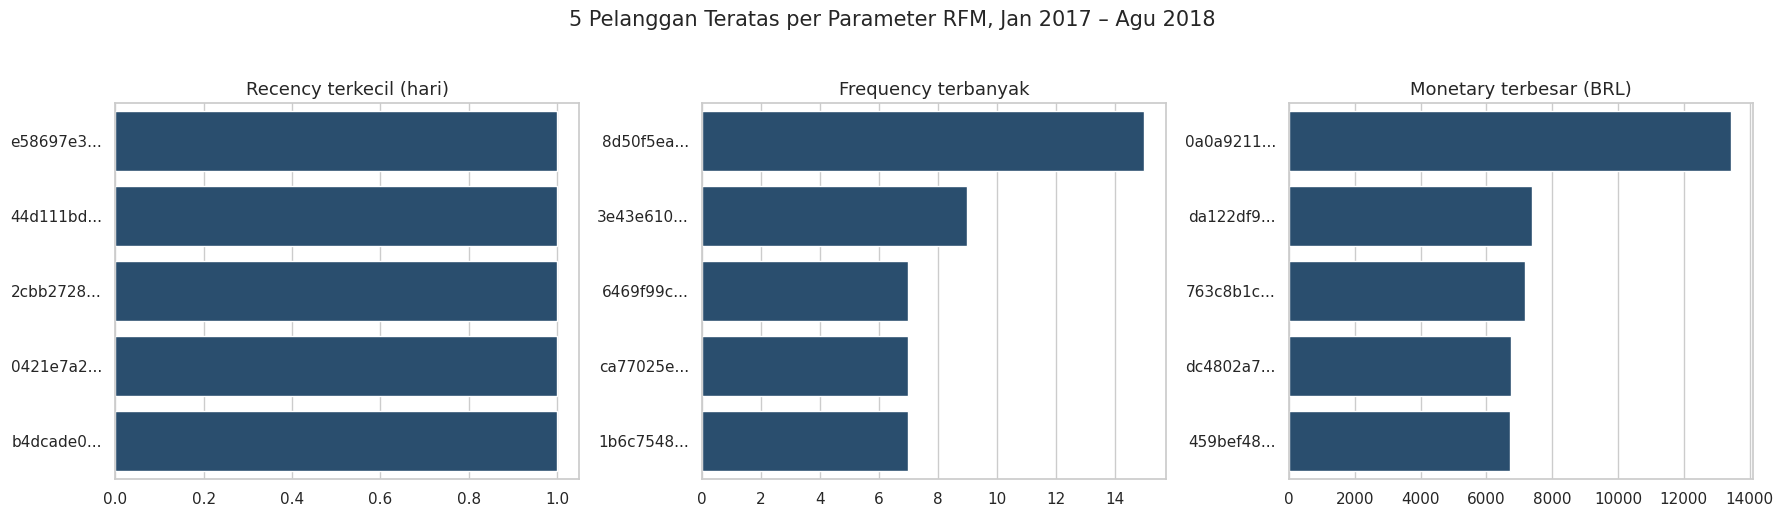

In [36]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for i, (col, asc, title) in enumerate([("recency", True, "Recency terkecil (hari)"),
                                       ("frequency", False, "Frequency terbanyak"),
                                       ("monetary", False, "Monetary terbesar (BRL)")]):
    d = rfm_df.sort_values(col, ascending=asc).head(5).copy()
    d["id"] = d["customer_unique_id"].str[:8] + "..."
    sns.barplot(data=d, y="id", x=col, color="#1f4e79", ax=ax[i])
    ax[i].set_title(title, fontsize=13)
    ax[i].set_ylabel(None)
    ax[i].set_xlabel(None)
plt.suptitle("5 Pelanggan Teratas per Parameter RFM, Jan 2017 – Agu 2018", fontsize=15, y=1.03)
plt.tight_layout()
plt.show()

### Clustering dengan Manual Grouping (berbasis skor RFM)
**Tujuan:** memberi label segmen yang mudah dipahami tanpa algoritma machine learning.
- **R_score** (1–5) dibuat dengan `pd.qcut` (binning kuantil); recency kecil = skor tinggi.
- **F_score** ditentukan dengan aturan bisnis karena sebagian besar pelanggan hanya belanja sekali: 1 pesanan = 1, 2 pesanan = 3, ≥3 pesanan = 5.
- **M_score** (1–5) dengan `pd.qcut` pada nilai monetary.
- Segmen ditentukan dengan aturan manual berdasarkan kombinasi skor tersebut.

In [37]:
rfm_df["R_score"] = pd.qcut(rfm_df["recency"], 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm_df["F_score"] = pd.cut(rfm_df["frequency"], bins=[0, 1, 2, np.inf], labels=[1, 3, 5]).astype(int)
rfm_df["M_score"] = pd.qcut(rfm_df["monetary"], 5, labels=[1, 2, 3, 4, 5]).astype(int)

def segment(row):
    if row["F_score"] >= 3 and row["R_score"] >= 4:
        return "Loyal Customer"
    if row["F_score"] >= 3:
        return "Repeat - At Risk"
    if row["R_score"] >= 4 and row["M_score"] >= 4:
        return "New High Spender"
    if row["R_score"] >= 4:
        return "New Customer"
    if row["R_score"] >= 2:
        return "Need Attention"
    return "Lost Customer"

rfm_df["segment"] = rfm_df.apply(segment, axis=1)

seg_summary = (rfm_df.groupby("segment")
               .agg(customers=("customer_unique_id", "count"),
                    avg_recency=("recency", "mean"),
                    avg_frequency=("frequency", "mean"),
                    avg_monetary=("monetary", "mean"),
                    total_monetary=("monetary", "sum"))
               .sort_values("customers", ascending=False))
seg_summary["share_customers_%"] = (seg_summary["customers"] / seg_summary["customers"].sum() * 100).round(1)
seg_summary.round(1)

,customers,avg_recency,avg_frequency,avg_monetary,total_monetary,share_customers_%
segment,,,,,,
Need Attention,35932,267.7,1.0,135.5,4869616.0,38.6
New Customer,21773,89.8,1.0,55.7,1212800.1,23.4
Lost Customer,18153,469.6,1.0,137.8,2502274.8,19.5
New High Spender,14449,91.9,1.0,267.8,3869732.0,15.5
Repeat - At Risk,1584,318.9,2.1,252.3,399650.4,1.7
Loyal Customer,1205,89.1,2.2,270.3,325704.6,1.3


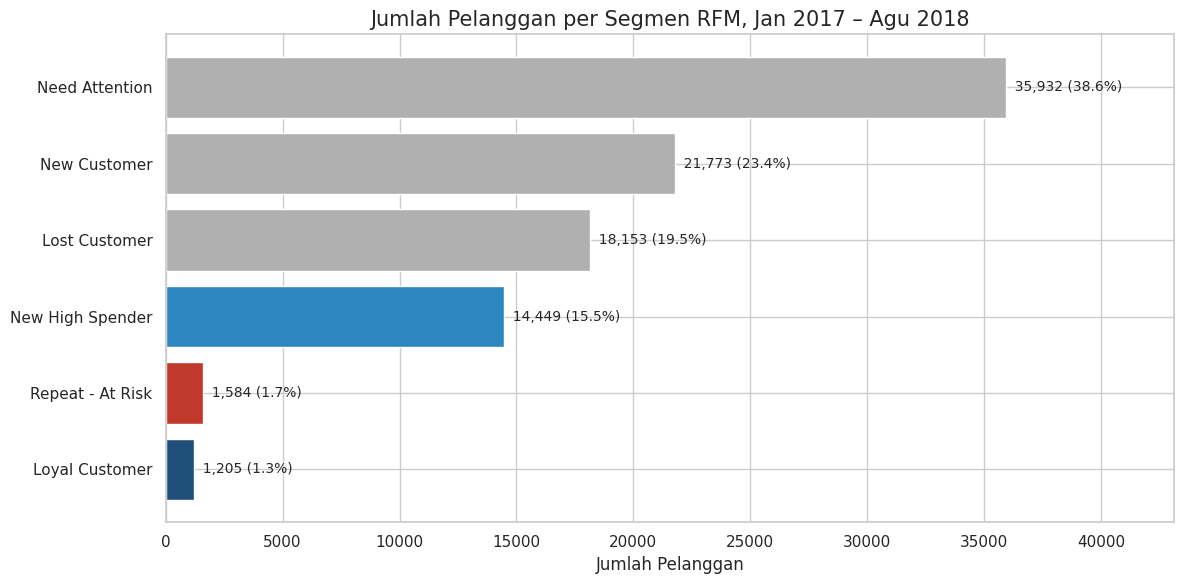

In [38]:
seg_plot = seg_summary.reset_index().sort_values("customers")
highlight = {"Loyal Customer": "#1f4e79", "New High Spender": "#2e86c1", "Repeat - At Risk": "#c0392b"}
colors = [highlight.get(s, "#b0b0b0") for s in seg_plot["segment"]]

fig, ax = plt.subplots(figsize=(12, 6))
ax.barh(seg_plot["segment"], seg_plot["customers"], color=colors)
for i, (v, p) in enumerate(zip(seg_plot["customers"], seg_plot["share_customers_%"])):
    ax.text(v, i, f"  {v:,} ({p}%)", va="center", fontsize=10)
ax.set_title("Jumlah Pelanggan per Segmen RFM, Jan 2017 – Agu 2018", fontsize=15)
ax.set_xlabel("Jumlah Pelanggan")
ax.set_xlim(0, seg_plot["customers"].max() * 1.2)
plt.tight_layout()
plt.show()

### Geospatial Analysis
**Tujuan:** melihat sebaran pelanggan dan revenue berdasarkan state untuk menentukan wilayah prioritas pemasaran dan logistik. Titik koordinat tiap state diambil dari median koordinat pada `geolocation_df` yang sudah dibersihkan.

In [39]:
state_df = (main_df.groupby("customer_state")
            .agg(customers=("customer_unique_id", "nunique"),
                 revenue=("price", "sum"),
                 late_rate=("is_late", "mean"))
            .reset_index()
            .merge(geo_state, left_on="customer_state", right_on="state", how="left")
            .drop(columns="state")
            .sort_values("revenue", ascending=False))
state_df["revenue_share_%"] = (state_df["revenue"] / state_df["revenue"].sum() * 100).round(1)
state_df.head(10)

,customer_state,customers,revenue,late_rate,lat,lng,revenue_share_%
25,SP,39058,5054516.95,0.057715,-23.503231,-46.707598,38.4
18,RJ,11879,1751433.85,0.130170,-22.843269,-43.262623,13.3
10,MG,10969,1548206.88,0.054593,-19.916392,-43.992764,11.7
22,RS,5150,726194.92,0.068999,-29.763730,-51.340969,5.5
17,PR,4750,664048.00,0.048051,-25.363555,-50.739188,5.0
23,SC,3441,504774.07,0.096474,-27.090941,-49.063261,3.8
4,BA,3155,493339.26,0.136957,-12.948131,-38.998427,3.7
6,DF,2013,295454.64,0.074563,-15.819274,-47.977417,2.2
8,GO,1889,281932.21,0.078855,-16.677822,-49.267274,2.1
7,ES,1925,267783.66,0.122412,-20.291963,-40.338605,2.0


In [44]:
brazil_map = folium.Map(
    location=[-14.2, -51.9],
    zoom_start=4,
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles &copy; Esri",
)
max_rev = state_df["revenue"].max()
for _, r in state_df.iterrows():
    folium.CircleMarker(
        location=[r["lat"], r["lng"]],
        radius=5 + 35 * np.sqrt(r["revenue"] / max_rev),
        color="#1f4e79", fill=True, fill_opacity=0.55, weight=1,
        tooltip=(f"{r['customer_state']}: {r['customers']:,} pelanggan | "
                 f"BRL {r['revenue']:,.0f} ({r['revenue_share_%']}%) | terlambat {r['late_rate']:.1%}"),
    ).add_to(brazil_map)
brazil_map

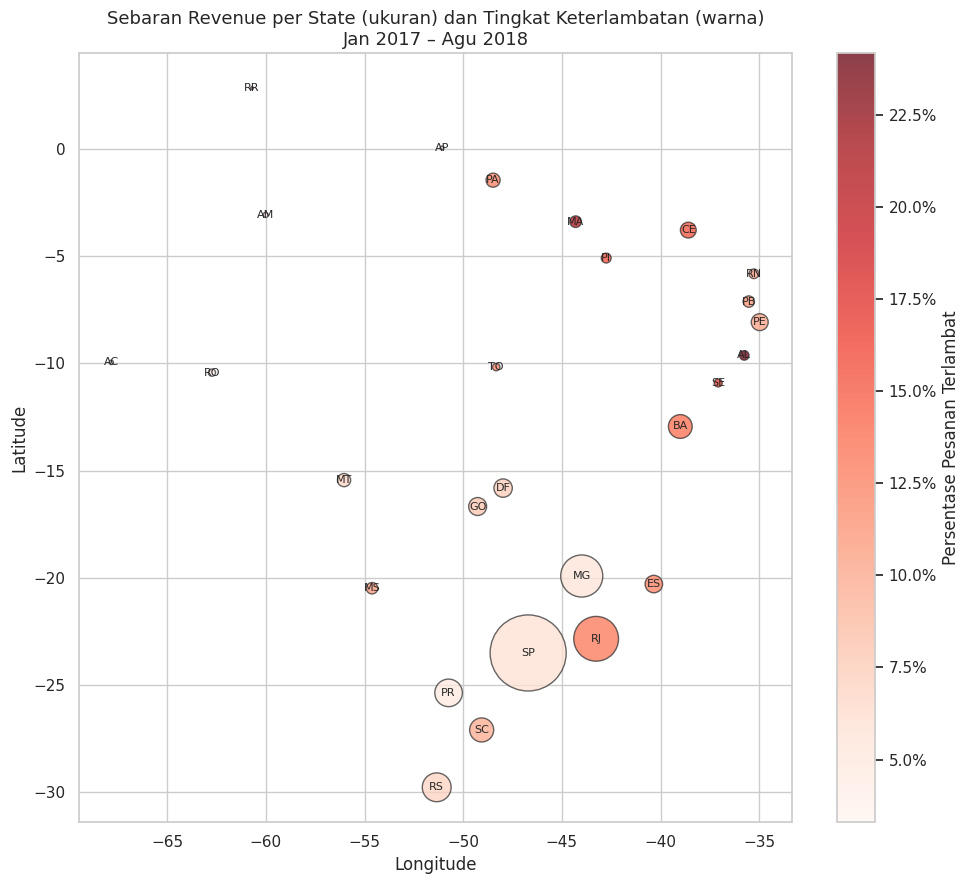

In [41]:
# Versi statis (tetap terlihat walau peta interaktif tidak ter-render)
fig, ax = plt.subplots(figsize=(10, 9))
sc = ax.scatter(state_df["lng"], state_df["lat"], s=state_df["revenue"] / max_rev * 3000,
                c=state_df["late_rate"], cmap="Reds", alpha=0.75, edgecolor="#333")
for _, r in state_df.iterrows():
    ax.text(r["lng"], r["lat"], r["customer_state"], ha="center", va="center", fontsize=8)
cb = plt.colorbar(sc, ax=ax, format=mtick.PercentFormatter(1.0))
cb.set_label("Persentase Pesanan Terlambat")
ax.set_title("Sebaran Revenue per State (ukuran) dan Tingkat Keterlambatan (warna)\nJan 2017 – Agu 2018", fontsize=13)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.tight_layout()
plt.show()

**Insight:**
- RFM: hampir semua pelanggan (sekitar 97%) hanya belanja sekali, dengan median recency 218 hari dan median monetary BRL 89,70. Retensi pelanggan menjadi masalah utama.
- Manual grouping: segmen terbesar adalah Need Attention (38,6%), lalu New Customer (23,4%) dan Lost Customer (19,5%). Loyal Customer hanya 1,3% (1.205 orang), sedangkan New High Spender cukup besar (15,5%) dan berpotensi diubah menjadi pelanggan loyal.
- Geospatial: revenue sangat terpusat di tenggara Brasil. SP sendiri menyumbang 38,4% revenue, disusul RJ (13,3%) dan MG (11,7%). State dengan revenue kecil di utara dan timur laut justru punya tingkat keterlambatan paling tinggi.

### Menyimpan Data untuk Dashboard

In [42]:
dashboard_cols = ["order_id", "customer_unique_id", "customer_state", "order_purchase_timestamp",
                  "order_delivered_customer_date", "order_estimated_delivery_date",
                  "product_category_name_english", "price", "freight_value", "review_score",
                  "is_late", "delivery_days"]
main_df[dashboard_cols].to_csv("dashboard/main_data.csv", index=False)
geo_state.to_csv("dashboard/geo_state.csv", index=False)
print("Tersimpan:", main_df[dashboard_cols].shape)

Tersimpan: (109872, 12)


## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Selama Jan 2017 – Agu 2018, 5 kategori dengan revenue tertinggi adalah health_beauty (BRL 1,23 juta), watches_gifts (BRL 1,16 juta), bed_bath_table (BRL 1,02 juta), sports_leisure (BRL 0,95 juta), dan computers_accessories (BRL 0,89 juta), yang bersama-sama menyumbang sekitar 40% revenue. 5 kategori terendah adalah security_and_services, fashion_childrens_clothes, cds_dvds_musicals, home_comfort_2, dan flowers, masing-masing dengan revenue di bawah BRL 1.200.
- **Conclusion pertanyaan 2:** Jumlah pesanan dan revenue tumbuh konsisten sepanjang 2017 dan mencapai puncak pesanan pada November 2017 (7.288 pesanan, didorong Black Friday 24 November). Pada 2018 penjualan stabil di level tinggi (sekitar 6.000–7.000 pesanan per bulan) dan tumbuh sekitar 140% dibanding periode yang sama tahun 2017, namun mulai stagnan sejak pertengahan 2018.
- **Conclusion pertanyaan 3:** Pesanan yang terlambat mendapat rata-rata skor review 2,57, sedangkan yang tepat waktu 4,29 (selisih 1,73 poin), dan 46% pesanan terlambat diberi bintang 1. Rata-rata keterlambatan nasional 8,1%, tetapi di AL, MA, dan PI mencapai 16–24%.

**Rekomendasi Action Item:**
- Fokuskan anggaran promosi pada 5 kategori teratas (terutama health_beauty dan watches_gifts), dan evaluasi kategori dengan revenue sangat rendah: tingkatkan visibilitasnya atau pertimbangkan untuk tidak diprioritaskan.
- Siapkan stok, kapasitas gudang, dan kurir tambahan mulai Oktober untuk menghadapi lonjakan Black Friday/November, serta buat kampanye baru untuk mendorong pertumbuhan yang mulai stagnan di 2018.
- Perbaiki logistik di state dengan keterlambatan tinggi (AL, MA, PI, CE, SE) dan RJ, misalnya dengan menambah mitra kurir lokal atau membuat estimasi waktu kirim yang lebih realistis, karena keterlambatan langsung menurunkan skor review.
- Buat program retensi (voucher pembelian kedua, program loyalitas) yang menyasar segmen New High Spender dan Need Attention, karena 97% pelanggan baru belanja sekali.